# 04 - Evaluation: baseline on the GSO test set

**WHAT:** tables and figures for the baseline on the 14-object GSO test set (CLIP mean and seed spread per object and per group, time per run), and later baseline vs improved. Owner: Hector.
**WHERE:** `notebooks/`. Runs on CPU, no container or GPU needed. Run top to bottom from `notebooks/` or the repo root. Writes figures and table CSVs to `figures/` (not committed; copies go on the Drive `figures/` folder).
**INPUTS:** `results/metrics.csv` (CLIP scores, Steven's `scripts/eval_clip.py`), `results/baseline_log.csv` (time, VRAM, Gaussian count, mesh size, Steven's `scripts/run_batch.py`), `data/gso_inputs/objects.csv` (the test set).
**WHY a notebook:** the scores come from the scripts; this turns them into the report and slide numbers, so every number in the write-up traces back to a results file.

**Protocol (paper, Table 1):** CLIP similarity (`laion/CLIP-ViT-bigG-14`) between the input image and 8 renders of the final mesh (azimuth 0 to 315 in 45 degree steps, elevation 0). Paper: **0.738** full pipeline, **0.678** stage 1 only. Our test set and GPU differ, so 0.738 is a reference point, not a like-for-like target.

**Rules:** 3 seeds per object (0, 1, 2), report mean and spread. Same seed still drifts between runs, so an improvement has to beat the seed spread shown here.

Runs on CPU (no GPU needed). Re-run top to bottom when new results land; the last section compares baseline vs improved once improved rows exist.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Repo root, whether the notebook is run from notebooks/ or from the root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "figures"          # local only (excluded); upload to the Drive figures/ folder
FIG_DIR.mkdir(exist_ok=True)

PAPER_FULL = 0.738      # DreamGaussian Table 1, full pipeline
PAPER_STAGE1 = 0.678    # DreamGaussian Table 1, stage 1 only
BASE_TAG = "gso_baseline"

pd.set_option("display.precision", 3)

## 1. Load and check the inputs

In [2]:
metrics = pd.read_csv(ROOT / "results/metrics.csv")
log = pd.read_csv(ROOT / "results/baseline_log.csv")
objects = pd.read_csv(ROOT / "data/gso_inputs/objects.csv")
gso_names = set(objects.short_name)

# Final meshes only (stage 2). eval_clip.py --stage 1 adds stage-1 rows under the same tag.
base = metrics[(metrics.tag == BASE_TAG) & (metrics.stage == 2)]
print("metrics rows by (tag, stage):", metrics.groupby(["tag", "stage"]).size().to_dict())
print("baseline rows:", len(base), "| objects:", base.name.nunique(), "| seeds:", sorted(base.seed.unique()))
print("status:", base.status.value_counts().to_dict())

# The baseline must cover every test-set object with all 3 seeds, all ok
assert set(base.name) == gso_names, set(base.name) ^ gso_names
assert (base.groupby("name").seed.nunique() == 3).all()
assert (base.status == "ok").all()

metrics rows by (tag, stage): {('gso_baseline', 2): 42}
baseline rows: 42 | objects: 14 | seeds: [np.int64(0), np.int64(1), np.int64(2)]
status: {'ok': 42}


## 2. Join CLIP scores with the run log

**Tag mismatch (logged in `CHANGELOG.md`, 2026-11-05):** `metrics.csv` tags these runs `gso_baseline`, but `baseline_log.csv` tags them `baseline`, the same tag as the 24 mini-baseline runs on the authors' sample images. So we can't join on `tag`. Workaround: keep only log rows whose image is a test-set object, then join on `(name, seed)`. The sample images and the test-set objects have no names in common, so this is unambiguous.

In [3]:
gso_log = log[log.image.isin(gso_names)].rename(columns={"image": "name"})
print("GSO rows in the log:", len(gso_log), "| commits:", gso_log.commit.unique(), "| configs:", gso_log.config.unique())

runs = base.merge(
    gso_log[["name", "seed", "total_s", "stage1_s", "stage2_s",
             "vram_stage1_mib", "gaussians_final", "final_f"]],
    on=["name", "seed"], how="left", validate="one_to_one",
)
assert len(runs) == 42 and runs.total_s.notna().all()
runs.head()

GSO rows in the log: 42 | commits: <StringArray>
['01e7a53']
Length: 1, dtype: str | configs: <StringArray>
['configs/image.yaml']
Length: 1, dtype: str


,tag,stage,name,seed,mesh,clip_sim,seconds,status,total_s,stage1_s,stage2_s,vram_stage1_mib,gaussians_final,final_f
0,gso_baseline,2,android,0,dreamgaussian/logs/baseline/android_s0.obj,0.728,8.3,ok,69.5,53.0,16.6,3382,39958,81276
1,gso_baseline,2,android,1,dreamgaussian/logs/baseline/android_s1.obj,0.722,7.1,ok,65.4,46.4,19.0,3407,40934,74006
2,gso_baseline,2,android,2,dreamgaussian/logs/baseline/android_s2.obj,0.718,7.4,ok,67.3,50.0,17.3,3375,41367,78438
3,gso_baseline,2,cartridge,0,dreamgaussian/logs/baseline/cartridge_s0.obj,0.437,7.8,ok,81.0,62.2,18.8,3379,44352,100000
4,gso_baseline,2,cartridge,1,dreamgaussian/logs/baseline/cartridge_s1.obj,0.413,8.2,ok,81.5,64.0,17.5,3378,49378,100000


## 3. Object groups

Groups come from the `notes` column of `objects.csv`, which was written before the baseline ran (commit `b32d258`). They are the hard cases we picked on purpose; everything else is "standard".

In [4]:
GROUPS = {
    "head-on (body hidden)": ["turtle", "shark", "orca"],
    "flat / printed": ["cartridge", "headset_box"],
    "two glossy figurines": ["cats"],
}
group_of = {name: g for g, names in GROUPS.items() for name in names}
runs["group"] = runs.name.map(group_of).fillna("standard")
objects[["short_name", "notes"]]

,short_name,notes
0,android,blocky figure; face front; thin antennae
1,cups,stacked cylinders; strong colors; rotationally...
2,horse,animal; side view; thin legs and tail
3,turtle,animal toy; 0_0 = head-on; shell length hidden...
4,trex,animal; side view; thin arms and tail
5,yoshi,character figure; face; thin arms
6,cats,TWO figurines (white + black); glossy/reflecti...
7,giraffe,plush toy; face; soft texture
8,cartridge,thin flat object; printed label; original GSO ...
9,headset_box,box; printed text and photo (label case)


## 4. Per-object results (mean and spread over 3 seeds)

In [5]:
per_obj = (
    runs.groupby(["name", "group"])
    .agg(clip_mean=("clip_sim", "mean"), clip_std=("clip_sim", "std"),
         clip_min=("clip_sim", "min"), clip_max=("clip_sim", "max"),
         time_s=("total_s", "mean"), gaussians=("gaussians_final", "mean"),
         faces=("final_f", "mean"))
    .reset_index()
    .sort_values("clip_mean", ascending=False)
)
per_obj["vs_paper"] = per_obj.clip_mean - PAPER_FULL
per_obj.to_csv(FIG_DIR / "table_per_object_baseline.csv", index=False, float_format="%.4f")
per_obj

,name,group,clip_mean,clip_std,clip_min,clip_max,time_s,gaussians,faces,vs_paper
3,cups,standard,0.842,0.005,0.837,0.848,57.467,21897.667,19178.667,0.104
13,yoshi,standard,0.832,0.009,0.822,0.839,62.367,37246.333,41665.333,0.094
6,horse,standard,0.829,0.009,0.819,0.836,57.533,31075.333,20499.333,0.091
11,trex,standard,0.755,0.011,0.745,0.766,57.633,33947.333,16639.333,0.017
7,lion,standard,0.741,0.010,0.732,0.750,59.867,41237.667,26974.000,0.003
10,squirrel,standard,0.730,0.005,0.725,0.734,68.200,48121.333,50851.333,-0.008
0,android,standard,0.722,0.005,0.718,0.728,67.400,40753.000,77906.667,-0.016
4,giraffe,standard,0.691,0.014,0.677,0.705,70.333,48613.333,85634.667,-0.047
2,cats,two glossy figurines,0.674,0.035,0.637,0.708,63.000,38956.333,56868.667,-0.064
9,shark,head-on (body hidden),0.664,0.038,0.621,0.694,73.533,46716.000,70792.667,-0.074


## 5. Headline numbers

- **Overall mean:** mean of all 42 runs (the same as the mean of the 14 object means, since every object has 3 seeds).
- **Overall spread:** compute the 14-object mean separately for each seed, then the std of those 3 numbers. This is how much the headline number moves from seed alone.

In [6]:
by_seed = runs.groupby("seed").clip_sim.mean()
summary = pd.Series({
    "overall CLIP mean": runs.clip_sim.mean(),
    "overall CLIP spread (std over seeds)": by_seed.std(),
    "paper, full pipeline": PAPER_FULL,
    "paper, stage 1 only": PAPER_STAGE1,
    "objects at or above 0.738": int((per_obj.clip_mean >= PAPER_FULL).sum()),
    "median per-object seed std": per_obj.clip_std.median(),
    "largest per-object seed std": per_obj.clip_std.max(),
    "mean time per run (s)": runs.total_s.mean(),
    "mean stage 1 / stage 2 (s)": f"{runs.stage1_s.mean():.1f} / {runs.stage2_s.mean():.1f}",
})
print("per-seed overall means:", by_seed.round(4).to_dict())

# Stage-1-only score (paper: 0.678), once Steven runs eval_clip.py --stage 1
s1 = metrics[(metrics.tag == BASE_TAG) & (metrics.stage == 1) & (metrics.status == "ok")]
summary["ours, stage 1 only"] = round(s1.clip_sim.mean(), 3) if len(s1) else "not run yet"
summary

per-seed overall means: {0: 0.6828, 1: 0.6838, 2: 0.6791}


overall CLIP mean                             0.682
overall CLIP spread (std over seeds)          0.002
paper, full pipeline                          0.738
paper, stage 1 only                           0.678
objects at or above 0.738                         5
median per-object seed std                    0.012
largest per-object seed std                   0.038
mean time per run (s)                         67.34
mean stage 1 / stage 2 (s)              49.9 / 17.4
ours, stage 1 only                      not run yet
dtype: object

In [7]:
per_group = (
    runs.groupby("group")
    .agg(objects=("name", "nunique"), clip_mean=("clip_sim", "mean"),
         clip_min=("clip_sim", "min"), clip_max=("clip_sim", "max"))
    .sort_values("clip_mean", ascending=False)
)
per_group.to_csv(FIG_DIR / "table_per_group_baseline.csv", float_format="%.4f")
print("Standard objects only:", round(runs[runs.group == "standard"].clip_sim.mean(), 3))
per_group

Standard objects only: 0.768


,objects,clip_mean,clip_min,clip_max
group,,,,
standard,8,0.768,0.677,0.848
two glossy figurines,1,0.674,0.637,0.708
head-on (body hidden),3,0.632,0.573,0.694
flat / printed,2,0.417,0.402,0.437


## 6. Figures

Colors: the 3 hard-case groups get their own color, standard objects are gray, so the eye goes to the hard cases. Every bar is also named on the axis and listed in the legend, so color is never the only cue.

In [8]:
COLORS = {
    "standard": "#a3a29c",
    "head-on (body hidden)": "#2a78d6",
    "flat / printed": "#eb6834",
    "two glossy figurines": "#1baf7a",
}
INK, MUTED = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
})

def ref_line(ax, x, label, ha="left"):
    """Vertical dashed reference line, labeled just above the plot area."""
    ax.axvline(x, color=MUTED, linestyle="--", linewidth=1, zorder=1)
    ax.text(x, 1.01, label, color=MUTED, fontsize=9, ha=ha, va="bottom",
            transform=ax.get_xaxis_transform())

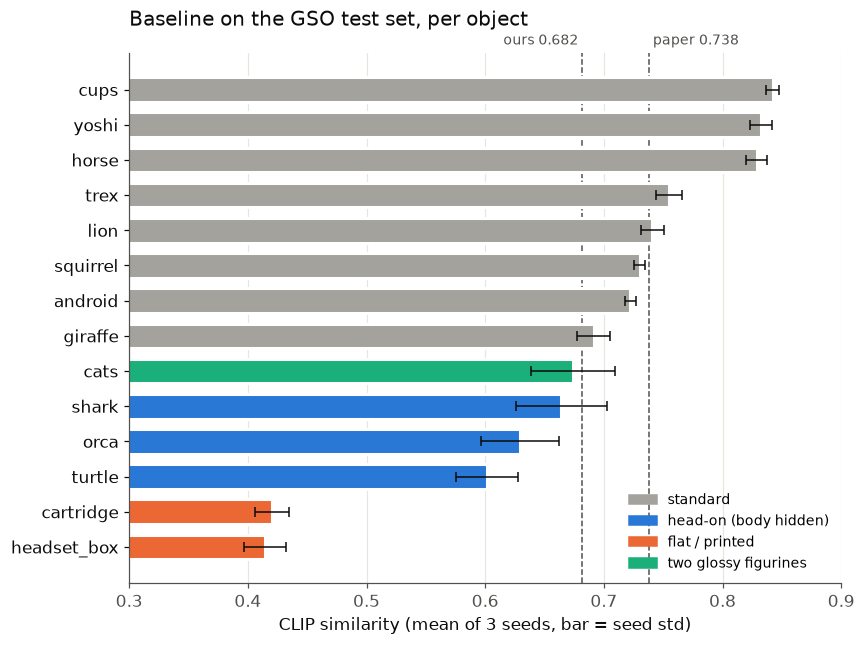

In [9]:
# Figure 1: mean CLIP per object, error bars = seed std
order = per_obj.sort_values("clip_mean")            # lowest at the bottom
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(order.name, order.clip_mean, height=0.7,
        xerr=order.clip_std, error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 3},
        color=order.group.map(COLORS), edgecolor="white", linewidth=2, zorder=2)

ref_line(ax, PAPER_FULL, " paper 0.738")
ref_line(ax, runs.clip_sim.mean(), f"ours {runs.clip_sim.mean():.3f} ", ha="right")

ax.set_xlim(0.3, 0.9)
ax.set_xlabel("CLIP similarity (mean of 3 seeds, bar = seed std)")
ax.set_title("Baseline on the GSO test set, per object", loc="left", color=INK, pad=18)
ax.grid(axis="x", color="#e6e5e0", zorder=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()]
ax.legend(handles, COLORS.keys(), loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_clip_per_object.png", bbox_inches="tight")
plt.show()

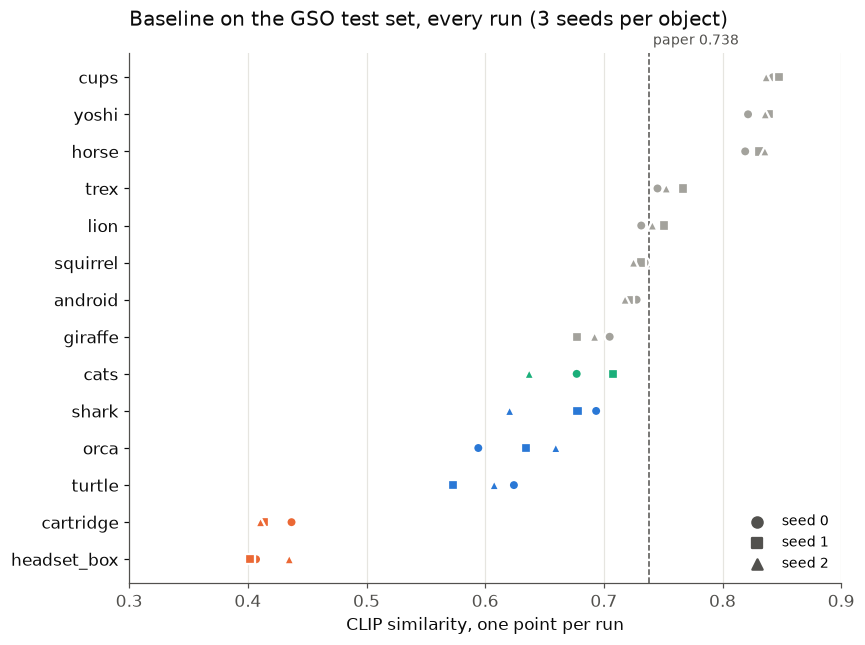

In [10]:
# Figure 2: every seed as a dot, to show seed noise vs differences between objects
fig, ax = plt.subplots(figsize=(8, 6))
ypos = {name: i for i, name in enumerate(order.name)}
for seed, marker in zip([0, 1, 2], ["o", "s", "^"]):
    s = runs[runs.seed == seed]
    ax.scatter(s.clip_sim, s.name.map(ypos), marker=marker, s=45,
               color=s.group.map(COLORS), edgecolors="white", linewidths=1.5,
               label=f"seed {seed}", zorder=3)
ax.set_yticks(range(len(order)), order.name)
ref_line(ax, PAPER_FULL, " paper 0.738")
ax.set_xlim(0.3, 0.9)
ax.set_xlabel("CLIP similarity, one point per run")
ax.set_title("Baseline on the GSO test set, every run (3 seeds per object)", loc="left", color=INK, pad=18)
ax.grid(axis="x", color="#e6e5e0", zorder=0)
leg = ax.legend(loc="lower right", frameon=False, fontsize=9)
for h in leg.legend_handles:
    h.set_color(MUTED)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_clip_seed_spread.png", bbox_inches="tight")
plt.show()

## 7. What this says (draft notes for the report, check before using)

Numbers below are printed from the tables above so the text can't drift from the data.

In [11]:
flat = per_obj[per_obj.group == "flat / printed"]
headon = per_obj[per_obj.group == "head-on (body hidden)"]
print(f"- Overall {runs.clip_sim.mean():.3f} vs paper {PAPER_FULL} (different test set and GPU).")
print(f"- Standard objects alone: {runs[runs.group == 'standard'].clip_sim.mean():.3f}.")
print(f"- Flat / printed objects collapse: {', '.join(f'{r.name} {r.clip_mean:.3f}' for r in flat.itertuples())}.")
print(f"- Head-on objects sit below the standard set: {', '.join(f'{r.name} {r.clip_mean:.3f}' for r in headon.itertuples())}.")
print(f"- Seed std per object: median {per_obj.clip_std.median():.3f}, max {per_obj.clip_std.max():.3f} ({per_obj.loc[per_obj.clip_std.idxmax(), 'name']}).")
print(f"- Time per run: {runs.total_s.mean():.1f} s on the RTX 5070 (paper: about 2 min on a V100).")

- Overall 0.682 vs paper 0.738 (different test set and GPU).
- Standard objects alone: 0.768.
- Flat / printed objects collapse: cartridge 0.420, headset_box 0.415.
- Head-on objects sit below the standard set: shark 0.664, orca 0.629, turtle 0.602.
- Seed std per object: median 0.012, max 0.038 (shark).
- Time per run: 67.3 s on the RTX 5070 (paper: about 2 min on a V100).


## 8. Baseline vs improved (runs automatically once improved rows exist)

Pairs each improved run with the baseline run of the same object and seed. A change only counts if it is clearly bigger than that object's seed spread.

In [12]:
other_tags = [t for t in metrics.tag.unique() if t != BASE_TAG]
if not other_tags:
    print("No improved runs in metrics.csv yet. Re-run this notebook after Steven's improved eval.")
else:
    for tag in other_tags:
        imp = metrics[(metrics.tag == tag) & (metrics.stage == 2) & (metrics.status == "ok")]
        paired = base.merge(imp, on=["name", "seed"], suffixes=("_base", "_imp"))
        paired["delta"] = paired.clip_sim_imp - paired.clip_sim_base
        cmp = (paired.groupby("name")
               .agg(base=("clip_sim_base", "mean"), improved=("clip_sim_imp", "mean"),
                    delta=("delta", "mean"))
               .join(per_obj.set_index("name").clip_std.rename("base_seed_std")))
        cmp["beats_noise"] = cmp.delta.abs() > 2 * cmp.base_seed_std
        print(f"{tag}: {len(paired)} paired runs, mean delta {paired.delta.mean():+.4f}")
        display(cmp.sort_values("delta"))

No improved runs in metrics.csv yet. Re-run this notebook after Steven's improved eval.
